## 회귀 모델 (알고리즘)
- 회귀: 연속적인 수치(숫자)를 예측하는 모델
- 분류 vs 회귀
    - 분류: 범주(ex. up/down)를 예측하며, 예측이 맞았는지 틀렸는지가 명확하다. (혼동행렬, 정확도 등으로 판단)
    - 회귀: 연속적인 수치(ex. 수익률)를 예측하며, 정확히 맞았다는 개념이 없어 오차의 크기를 측정한다. (MAE, RMSE, R² 등으로 판단)
> **회귀에서는 오차의 크기(즉, 실제와 얼마나 가까운지)가 가장 중요**\
> 참고: **로지스틱 회귀**는 이름만 회귀이고, 선형 계산 후 확률을 통해 범주를 판단하는 **분류 모델**이다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _ml import build_dataset, time_split, FEATURES, SEED
from _style import setup

setup()
pd.set_option("display.width", 130)

df = build_dataset()
train, test, cutoff = time_split(df)

# 데이터 샘플 추출
tr = train.sample(15_000, random_state=SEED)
te = test.sample(4_000, random_state=SEED)

# 피처 분리
X_train, X_test = tr[FEATURES], te[FEATURES]

# 정답(y)을 두 종류(분류(target_up)와 회귀(target_ret))로 준비
# 분류용 정답: 상승(1) / 하락 및 유지(0)
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]
# 회귀용 정답: 수익률(수치)
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]

print(f"* 학습: {len(tr):,}행"
      f" ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f"* 테스트: {len(te):,}행"
      f" ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f"* 피처 {len(FEATURES)}개")
print()
print(f"- 분류용 정답(target_up): {y_train_cls.unique()} (범주)")
print(f"- 회귀용 정답(target_ret):"
      f" {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f} (수치)")

* 학습: 15,000행 (2023-10-24 ~ 2026-01-16)
* 테스트: 4,000행 (2026-01-19 ~ 2026-09-07)
* 피처 7개

- 분류용 정답(target_up): [0 1] (범주)
- 회귀용 정답(target_ret): -0.2260 ~ 0.2313 (수치)


- 분류: y = target_up (0/1) --> RandomForestClassifier
- 회귀: y = target_ret (수익률) --> RandomForestRegressor

**동일한 이름의 알고리즘이지만, 평가 방법은 완전히 다르다.**
- RandomForestClassifier: accuracy_score(정확도), f1_score(f1 점수)
- RandomForestRegressor: mean_absolute_error, mean_squared_error, r2_score

In [2]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

                            # 분류 평가지표
from sklearn.metrics import (accuracy_score, f1_score,
                            # 회귀 평가지표
                             mean_absolute_error, mean_squared_error, r2_score)

# n_estimators는 기본값이 100이라 생략 가능
clf = RandomForestClassifier(n_estimators=100, max_depth=6,
                             random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6,
                            random_state=SEED, n_jobs=-1)

# 학습: fit(X_train, y_train)
clf.fit(X_train, y_train_cls)   # 분류 모델 학습
reg.fit(X_train, y_train_reg)   # 회귀 모델 학습

# 예측: predict(X_test)
pred_cls = clf.predict(X_test)    # 분류 모델 예측
pred_reg = reg.predict(X_test)    # 회귀 모델 예측

print(f"{'':<14}{'분류':<32}{'회귀'}")
print("-" * 70)
print(f"{'정답예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측예시':<13}{pred_cls[0]:<32}{pred_reg[0]:.4f}")
print()
print(f"분류 평가: 정확도 {accuracy_score(y_test_cls, pred_cls):.4f}")
print(f"           f1     {f1_score(y_test_cls, pred_cls):.4f}")
print(f"회귀 평가: RMSE {np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.6f}")
print(f"           R²   {r2_score(y_test_reg, pred_reg):.4f}")

              분류                              회귀
----------------------------------------------------------------------
정답예시         0                               -0.0068
예측예시         1                               -0.0000

분류 평가: 정확도 0.4933
           f1     0.4269
회귀 평가: RMSE 0.027389
           R²   -0.0068


In [3]:
# 0을 기준으로 회귀 예측을 나누어서 분류

# df["target_ret"] = df.groupby("code")["close"].pct_change()
# 즉, target_ret의 값이 0보다 크면 up이 됨.
reg_to_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델의 예측값에서 0을 기준으로 범주화 했을 때 정확도\n"
      f": {accuracy_score(y_test_cls, reg_to_cls):.4f}")
print(f"분류 모델로 학습한 정확도\n"
      f": {accuracy_score(y_test_cls, pred_cls):.4f}")

회귀 모델의 예측값에서 0을 기준으로 범주화 했을 때 정확도
: 0.4793
분류 모델로 학습한 정확도
: 0.4933


---
## LinearRegression (선형 회귀)
가장 단순한 선형 회귀 모델. 직선으로 관계를 표현.
`예측값 = w₁x + w₂x + ... + b`
(현재 데이터에서는 `예측값 = w₁ret_1d + w₂ret_5d + ... + b`)

- 학습: **MSE가 가장 작아지는** 가중치(w)와 절편(b)을 찾는 것.
    - w (가중치, 계수, 기울기): 다른 피처가 그대로일 때, 해당 피처가 1 증가할 때 예측값의 변화량
    - b (절편): 편향


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
# 각 피처의 평균을 0, 표준편차를 1로 맞춰주는 스케일러
from sklearn.preprocessing import StandardScaler

def make(model):
    return Pipeline([
        ("sc", StandardScaler()),
        ("m", model)
        ])

lin = make(LinearRegression())

lin.fit(X_train, y_train_reg)

# 절편(b), 계수(w) 확인
# lin.named_steps["m"]: 모델 객체를 추출
# 모델.coef_: 가중치(계수) 배열
coef = pd.Series(lin.named_steps["m"].coef_, index=FEATURES).sort_values()

# 모델.intercept_: 절편(편향) 값 확인
intercept = lin.named_steps["m"].intercept_

print(f"* 절편 b = {intercept:.6f}\n")
print("* 가중치 w")
print(coef.round(6).to_string())

* 절편 b = -0.000063

* 가중치 w
vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756


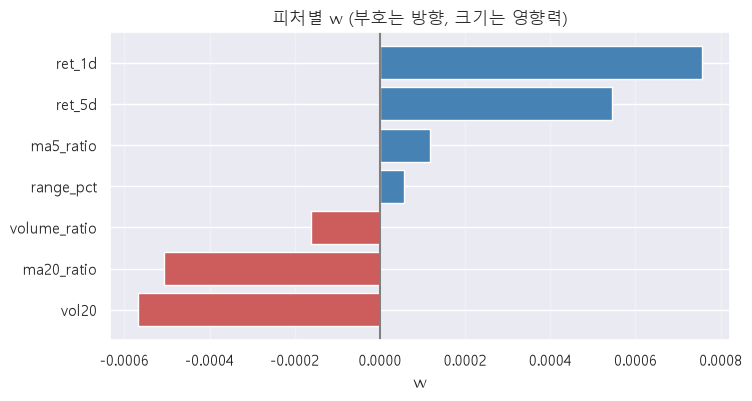

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

# 0 이상은 파랑, 0 미만은 빨강으로 표시
colors = ["indianred" if v < 0 else "steelblue" for v in coef.values]

ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="gray")
ax.set_xlabel("w")
ax.set_title("피처별 w (부호는 방향, 크기는 영향력)")
ax.grid(alpha=0.3, axis="x")

plt.show()

#### 계수(가중치)는 해석을 도와주는 지표
계수의 부호는 방향(+는 증가, -는 감소)을, 절댓값은 영향력의 크기를 알려준다.\
다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 한다.

또한 피처끼리 서로 비슷하면(다중공산성) 계수가 불안정해져서 해석이 틀어질 수 있다.\
(우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로, 선형 관계가 거의 없다고 볼 수 있다.)

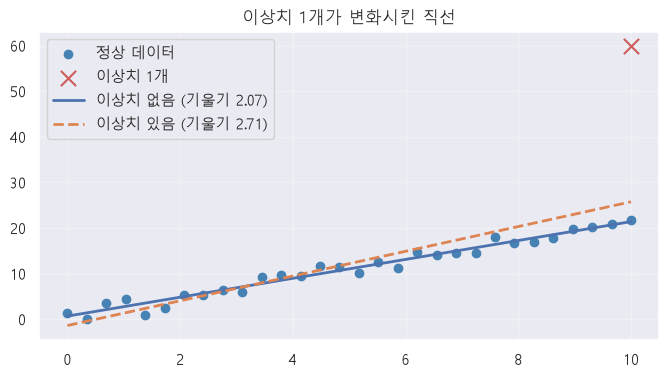

In [6]:
# 이상치를 하나 넣어서 직선의 변화를 확인해보기

# 난수 생성기
rng = np.random.default_rng(SEED)

# 폐구간 [0 10]의 30등분점 목록
x_demo = np.linspace(0, 10, 30)
# y = 2x + 1에 노이즈 추가 (평균 0, 표준편차 1.5인 오차 30개)
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

# 이상치 1개 추가 (x = 10이면 y ≒ 21 근처여야 하는데, y = 60)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(x_demo, y_demo, label="정상 데이터", color="steelblue")
ax.scatter([10], [60], s=120, label="이상치 1개", color="indianred", 
           marker="x", zorder=5)

datas = [
    # (x, y, display, name)
    (x_demo, y_demo, "-", "이상치 없음"),
    (x_bad, y_bad, "--", "이상치 있음")
]

for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1, 1), ys)

    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1, 1)), d,
            lw=2, label=f"{name} (기울기 {m.coef_[0]:.2f})")

ax.legend()
ax.grid(alpha=0.3)
ax.set_title("이상치 1개가 변화시킨 직선")

plt.show()

#### 이상치 하나가 직선을 끌고가는 것을 확인할 수 있다.

선형 회귀는 오차의 제곱을 최소화한다. 크게 빗나간 데이터(이상치)가 제곱되면서 영향력이 매우 커지게 된다.

---

## 규제 회귀 -  Ridge, Lasso, ElasticNet

피처가 많아지면 모델이 학습 데이터의 잡음까지 외우게 되고, 계수가 비정상적으로 커지면서 과적합이 일어나게 된다.\
규제는 **계수가 커지는 것에 벌점**을 주어 이를 막는 방법이다.

`비용 = 오차(MSE) + 벌점` (절편 b는 벌점 대상이 아니다.)

||Ridge(L2)|Lasso(L1)|ElasticNet|
|:--:|:--:|:--:|:--:|
|벌점|계수의 제곱합|계수의 절댓값 합|둘을 섞음 (`l1_ratio`로 비율 조절)|
|효과|계수를 골고루 축소|중요도가 낮은 계수를 0으로 제거|중간|
|결과|모든 피처 유지 (0이 되지 않음)|피처 선택 효과|상관된 피처가 많을 때 유용하다.|
> 주의: 동일한 `alpha`를 사용한다고 해서, Ridge와 Lasso의 규제 세기가 동일하지 않음.\
>       (내부 구현 오차 항 배율이 다르다.)

In [7]:
print(1e-4)
print(1e4)

0.0001
10000.0


In [8]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    # 규제 없는 기본 선형 회귀
    "Linear": make(LinearRegression()),
    # 규제가 약한 Ridge: 계수를 조금 줄인 모델
    "Ridge(a=1)": make(Ridge(alpha=1.0)),
    # 규제가 강한 Ridge: 계수를 많이 줄인 모델
    "Ridge(a=1000)": make(Ridge(alpha=1_000.0)),
    # 규제가 약한 Lasso: 일부 계수만 0으로 제거한 모델
    # (1e-4 = 10의 (-4)제곱)
    "Lasso(a=1e-4)": make(Lasso(alpha=1e-4)),
    # 규제가 강한 Lasso: 불필요한 계수를 0으로 제거
    "Lasso(a=1e-3)": make(Lasso(alpha=1e-3)),
    # l1_ratio=0.5: l1(Lasso) 규제의 벌점 비율
    #            => Lasso와 Ridge의 벌점 비율을 1:1로 사용
    "ElasticNet": make(ElasticNet(alpha=1e-4, l1_ratio=0.5))
}

coef_table = {}

for name, model in models.items():
    model.fit(X_train, y_train_reg)
    coef_table[name] = model.named_steps["m"].coef_

coef_df = pd.DataFrame(coef_table, index=FEATURES)
print(coef_df.round(6).to_string())
print()

for col in ["Lasso(a=1e-4)", "Lasso(a=1e-3)"]:
    zero_features = [f for f, v in coef_df[col].items() if v == 0]
    print(f"{col}일 때 0이 된 피처\n"
          f" ({len(zero_features)}개 : {zero_features})")

                Linear  Ridge(a=1)  Ridge(a=1000)  Lasso(a=1e-4)  Lasso(a=1e-3)  ElasticNet
ret_1d        0.000756    0.000756       0.000657       0.000659            0.0    0.000707
ret_5d        0.000544    0.000544       0.000380       0.000132            0.0    0.000339
ma5_ratio     0.000117    0.000117       0.000235       0.000133            0.0    0.000124
ma20_ratio   -0.000507   -0.000506      -0.000392      -0.000058            0.0   -0.000282
vol20        -0.000567   -0.000567      -0.000528      -0.000460            0.0   -0.000510
volume_ratio -0.000161   -0.000161      -0.000151      -0.000058            0.0   -0.000107
range_pct     0.000055    0.000055       0.000046       0.000000            0.0    0.000000

Lasso(a=1e-4)일 때 0이 된 피처
 (1개 : ['range_pct'])
Lasso(a=1e-3)일 때 0이 된 피처
 (7개 : ['ret_1d', 'ret_5d', 'ma5_ratio', 'ma20_ratio', 'vol20', 'volume_ratio', 'range_pct'])


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

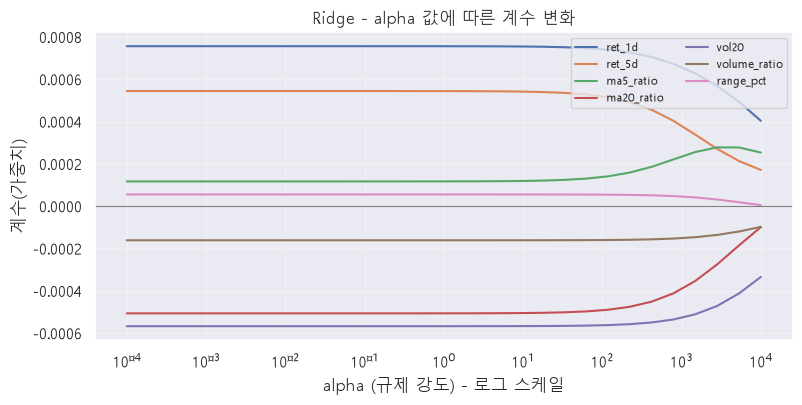

In [9]:
# alpha 값을 키우면 계수가 어떻게 줄어드는지 확인

# 0.0001 ~ 10_000  구간을 로그 스케일 간격으로 30개로 나누기
# linspace의 로그 버전
alphas = np.logspace(-4, 4, 30)

path = []

for a in alphas:
    m = make(Ridge(alpha=a))
    m.fit(X_train, y_train_reg)
    path.append(m.named_steps["m"].coef_)

# list -> ndarray (alpha 개수, 피처 개수)로 변환
path = np.array(path)

fig, ax = plt.subplots(figsize=(9, 4))

for i, f in enumerate(FEATURES):
    ax.plot(alphas, path[:, i], label=f)

ax.set_xscale("log")
ax.axhline(0, color="gray", lw=0.8)

ax.set_xlabel("alpha (규제 강도) - 로그 스케일")
ax.set_ylabel("계수(가중치)")
ax.set_title("Ridge - alpha 값에 따른 계수 변화")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

#### alpha(규제 강도)를 너무 키우면 과소 적합이 된다.

규제가 강해질수록 계수가 전부 0에 가까워지고, 모델은 사실상 아무것도 학습하지 못한다.
(그래프에서도 계수가 0으로 수렴함.)

> 적절한 alpha 값은 데이터마다 다르다.

#### 피처를 골라주는 Lasso
Lasso는 불필요한 피처의 계수를 아예 0으로 만들어 모델에서 제외한다.\
위 표에서 `alpha=1e-4`일 때는 `range_pct`만 제외되었으나, `alpha=1e-3`일 때는 7개의 피처가 모두 제외되었다.

이번 데이터 기준으로 `alpha=1e-3`부터는 규제가 너무 강해서 "아무것도 쓰지 못하고 평균만 예측하는 모델"이 된다.
=> **alpha 값은 타깃(y)과 계수의 크기에 맞춰 정해야 한다.**
(수익률처럼 y값이 아주 작은 데이터는 alpha 값도 작게 잡아야 한다.)

---

## KNN 회귀와 RandomForest 회귀

### KNN
> **KNeighborsClassifier**: 주변 k개의 **다수결**로 **범주** 결정\
> **KneighborsRegressor**: 주변 k개의 **평균**으로 **수치** 결정

### RandomForest
> **RandomForestClassifier**: 트리들의 **다수결**로 **범주** 결정\
> **RandomForestRegressor**: 트리들이 예측한 값의 **평균**으로 **수치** 결정

스케일링은 거리 기반인 KNN에 필요하고, 트리 계열에는 필요하지 않다.


In [10]:
from sklearn.neighbors import KNeighborsRegressor

models = {
    "기본값(평균)": None,
    "Linear": make(LinearRegression()),
    "Ridge(a=1.0)": make(Ridge(alpha=1.0)),
    "Lasso(a=1e-4)": make(Lasso(alpha=1e-4)),
    "KNN(k=50)": make(KNeighborsRegressor(n_neighbors=50, n_jobs=-1)),
    "RandomForest": RandomForestRegressor(n_estimators=100,
                                          n_jobs=-1,
                                          random_state=SEED,
                                          max_depth=6)
}

rows = []       # 모델별 평가 지표
preds = {}      # 모델별 예측 결과

for name, model in models.items():
    if model is None:
        # 학습 데이터의 평균만으로 직접 예측 (비교 기준선)
        pred = np.full(len(y_test_reg), y_train_reg.mean())
        r2_train = 0.0
    else:
        model.fit(X_train, y_train_reg)
        pred = model.predict(X_test)
        # score(): 분류 모델에서는 정확도를 나타내 주었으나,
        #          회귀 모델에서는 학습 데이터를 기준으로 R²를 반환한다.
        r2_train = model.score(X_train, y_train_reg)

    preds[name] = pred
    rows.append({
        "모델": name,
        "MAE": mean_absolute_error(y_test_reg, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
        "R² (테스트)": r2_score(y_test_reg, pred),
        "R² (학습)": r2_train
    })
print(pd.DataFrame(rows).round(6).to_string(index=False))


           모델      MAE     RMSE  R² (테스트)  R² (학습)
      기본값(평균) 0.017888 0.027297 -0.000001 0.000000
       Linear 0.017925 0.027317 -0.001506 0.001950
 Ridge(a=1.0) 0.017925 0.027317 -0.001506 0.001950
Lasso(a=1e-4) 0.017922 0.027313 -0.001204 0.001777
    KNN(k=50) 0.018125 0.027621 -0.023880 0.024733
 RandomForest 0.017967 0.027389 -0.006779 0.051433


### R² = 1 - (모델의 잔차 제곱합) / (평균 기준 잔차 제곱합)
|R²|의미|
|:--:|:--:|
|1.0|완벽|
|0.7|타깃 변동(분산)의 70%|
|0.0|평균으로 찍은 것과 동일|
|음수|평균으로 찍느니만 못함|

평균으로 예측한 결과를 기준으로 **다른 모델이 이 기준선보다 좋은지**를 판단해야 한다.
위 실행 결과를 보면 이번 데이터에서는 어떤 모델도 평균 기준선보다 좋은 지표를 만들지 못했다.
(R²의 테스트 결과를 기준으로 해석한 결론.)

또한, 랜덤포레스트는 학습 R²이 테스트 R²보다 매우 높다. 이를 통해 학습 데이터의 잡음을 일부 외운 **과적합** 신호로 볼 수 있다.

---

## 평가 지표 - MAE, MSE, RMSE, R²
회귀 모델의 평가 지표는 모두 **오차(잔차, 예측값 - 실제값)**를 사용하여 구한다.

- MAE : 오차 절댓값의 평균. 해석이 직관적이고 이상치에 덜 민감.
- MSE : 오차 제곱의 평균. 큰 오차에 큰 벌점 부여. 단위가 제곱이 되어 해석이 어렵다.
- RMSE: MSE의 제곱근. MSE의 장점 + 기존 단위로 해석 가능.
- R²  : 평균으로 찍을 때 대비 모델 점수. 단위가 없어 모델 간 비교에 유용함.

> 결과 보고 시 **MAE**, **RMSE**, **R²** 지표를 함께 보고한다.\
> (R²는 단위가 없으므로 같은 데이터에서 모델 간 비교에는 좋지만, 얼마만큼의 차이가 있는지를 설명하기가 어렵다.)

## 잔차 분석
`residual = y_test - pred`

In [11]:
pred_rf = preds["RandomForest"]
residual = y_test_reg.values - pred_rf

print("잔차 = 실제값 - 예측값")
print(f"    * 평균 {residual.mean():>12.6f}")
print(f"    표준편차 {residual.std():>12.6f}")
print(f"    * 최소: {residual.min():>12.6f}")
print(f"    * 최대: {residual.max():>12.6f}")

잔차 = 실제값 - 예측값
    * 평균     0.000095
    표준편차     0.027389
    * 최소:    -0.204308
    * 최대:     0.205061


> 0에 가까운 잔차 평균 => 어느 한 쪽으로 쏠려서 예측하지는 않았음을 의미한다.\
> **주의!** 평균 = 0이라고 해서 잘 맞추는 모델을 의미하지는 않는다.

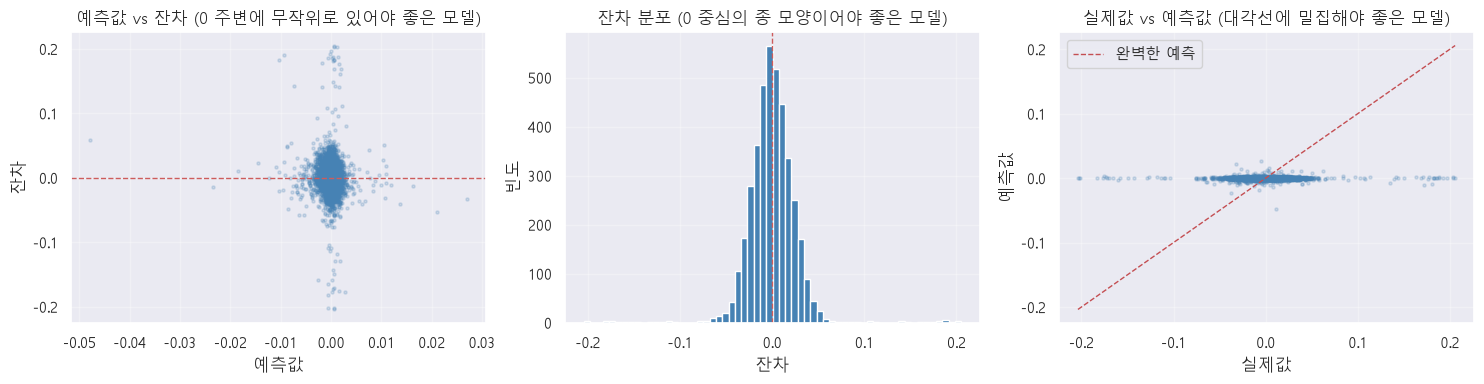

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. 예측값 vs 잔차
axes[0].scatter(pred_rf, residual, s=5, alpha=0.2, color="steelblue")
axes[0].axhline(0, color="indianred", ls="--", lw=1)
axes[0].set_xlabel("예측값")
axes[0].set_ylabel("잔차")
axes[0].set_title("예측값 vs 잔차 (0 주변에 무작위로 있어야 좋은 모델)")
axes[0].grid(alpha=0.3)

# 2. 잔차 히스토그램
axes[1].hist(residual, bins=60, color="steelblue")
axes[1].axvline(0, color="indianred", ls="--", lw=1)
axes[1].set_xlabel("잔차")
axes[1].set_ylabel("빈도")
axes[1].set_title("잔차 분포 (0 중심의 종 모양이어야 좋은 모델)")
axes[1].grid(alpha=0.3)

# 3. 실제값 vs 예측값
axes[2].scatter(y_test_reg, pred_rf, s=5, alpha=0.2, color="steelblue")
low, high = y_test_reg.min(), y_test_reg.max()
axes[2].plot([low, high], [low, high], "r--", lw=1, label="완벽한 예측")
axes[2].set_xlabel("실제값")
axes[2].set_ylabel("예측값")
axes[2].set_title("실제값 vs 예측값 (대각선에 밀집해야 좋은 모델)")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

#### 3번째 그래프 (실제값 vs 예측값)
실제값은 -0.2 ~ 0.2 범위에 있는데 반해, 예측값은 전부 0 근처에 몰려 있다.\
이것은 "이 모델이 거의 설명하지 못한다"는 것을 보여준다. 모델이 사실상 평균 근처만 예측하고 있다는 의미이다. RMSE가 실제 수익률의 표준편차와 거의 같음을 숫자로도 확인 가능하다.

---

## 트리 모델은 학습 데이터 범위 밖의 값을 예측할 수 없다.

- 외삽: 학습 데이터 범위 **밖**의 값을 예측
- 내삽: 학습 데이터 범위 **안**의 값을 예측

트리 모델의 예측값은 학습에 사용된 **타깃 값들의 평균**이므로, 학습한 타깃 범위를 벗어날 수 없다. 반면에, 선형 회귀 모델은 직선을 연장하여 범위 밖의 값도 예측할 수 있다.

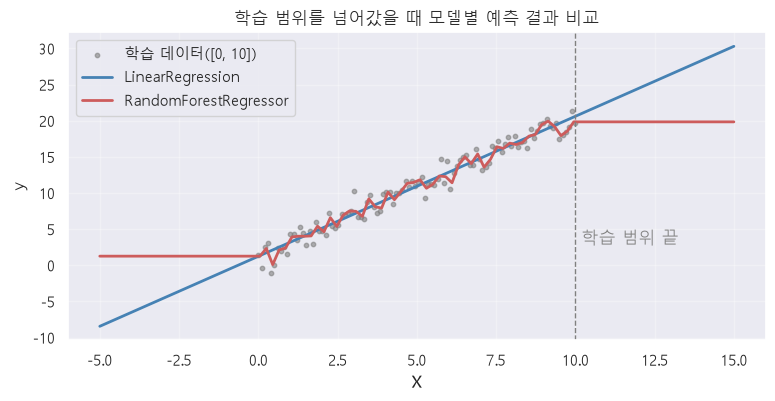

In [13]:
# 학습 데이터 범위: 0 ~ 10
x_fit = np.linspace(0, 10, 100)
# y = 2x + 1 + 노이즈
rng = np.random.default_rng(SEED)
y_fit = 2 * x_fit + 1 + rng.normal(0, 1.5, 100)

# 예측 데이터 범위: -5 ~ 15
x_new = np.linspace(-5, 15, 100)

lin_demo = LinearRegression().fit(x_fit.reshape(-1, 1), y_fit)
rf_demo = (RandomForestRegressor(
            n_estimators=100, 
            random_state=SEED)).fit(x_fit.reshape(-1, 1), y_fit)

fig, ax = plt.subplots(figsize=(9, 4))

ax.scatter(x_fit, y_fit, s=10, color="gray", alpha=0.6, label="학습 데이터([0, 10])")
ax.plot(x_new, 
        lin_demo.predict(x_new.reshape(-1, 1)),
        color="steelblue", lw=2, label="LinearRegression")
ax.plot(x_new, 
        rf_demo.predict(x_new.reshape(-1, 1)), 
        color="indianred", lw=2, label="RandomForestRegressor")
ax.axvline(10, color="gray", ls="--", lw=1)
ax.text(10.2, 3, "학습 범위 끝", color="gray")
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.set_title("학습 범위를 넘어갔을 때 모델별 예측 결과 비교")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

랜덤 포레스트는 `x=0`이나 `x=10`을 넘어가면 더 이상 값이 올라가지 않고 상수함수와 같은 그래프가 된다.\
선형 회귀는 직선을 그대로 연장하여 `x=15`에서도 실제 관계와 가까운 값을 예측한다.

랜덤 포레스트의 경우, 학습 기간에 없던 큰 변화가 생겼을 때 학습 때 보았던 값 근처에서만 예측을 하게 될 것이다.